#Instalando / importando pacotes e definindo configurações

In [ ]:
!pip install numpy -q
!pip install huggingface-hub -q
!pip install llama-index -q
!pip install llama-index-core -q
!pip install llama-index-llms-groq -q
!pip install llama-index-experimental -q
!pip install gradio -q
!pip install fpdf2 -q
!pip install mistralai -q
!pip install chardet -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.9/11.9 MB 46.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 24.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.8/166.8 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 818.2/818.2 kB 34.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 169.4/169.4 kB 6.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
torch 2.11.0+cpu requires setuptools<82, but you have setuptools 84.0.0 which is incompatible.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.7/77.7 kB 2.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.7/91.7 kB 4.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import pandas as pd
import numpy
import gradio as gr
import chardet
from mistralai.client import Mistral
from llama_index.core import Settings, PromptTemplate
from llama_index.llms.groq import Groq
from llama_index.core.query_engine import CustomQueryEngine
from llama_index.core.workflow import Workflow, step, Event, StartEvent, StopEvent
from llama_index.experimental.query_engine.pandas import PandasInstructionParser
from google.colab import userdata
from fpdf import FPDF
from datetime import datetime

In [ ]:
key = userdata.get('GROQ_API')

Settings.llm = Groq(model='openai/gpt-oss-20b', api_key=key)

url = 'https://raw.githubusercontent.com/PRBerlanda/LlamaIndex/refs/heads/CSV-Query-Reader/vendas.csv'
df = pd.read_csv(url)

llm = Groq(model='openai/gpt-oss-20b', api_key=key)

#Prompt Completo

In [ ]:
# Função para carregar os dados
def carregar_dados(caminho_arquivo, df_estado):
    if caminho_arquivo is None or caminho_arquivo == "":
        return "Por favor, faça o upload de um arquivo CSV para analisar.", pd.DataFrame(), df_estado
    try:
        df = pd.read_csv(caminho_arquivo)
        return "Arquivo carregado com sucesso!", df.head(), df
    except Exception as e:
        return f"Erro ao carregar arquivo: {str(e)}", pd.DataFrame(), df_estado

# Função para processar a pergunta
def processar_pergunta(pergunta, df_estado):
    if df_estado is not None and pergunta:
        qp = pipeline_consulta(df_estado)
        resposta = qp.run(query_str=pergunta)
        return resposta.message.content
    return ""

# Função para adicionar a pergunta e a resposta ao historico
def add_historico(pergunta, resposta, historico_estado):
    if pergunta and resposta:
        historico_estado.append((pergunta, resposta))
        gr.Info("Adicionado ao PDF!", duration=2)
        return historico_estado

# Função para gerar o PDF
def gerar_pdf(historico_estado):
    if not historico_estado:
        return "Nenhum dado para adicionar ao PDF.", None

    # Gerar nome de arquivo com timestamp
    timestamp = datetime.now().strftime("%Y%m%d%H%M%S")
    caminho_pdf = f"relatorio_perguntas_respostas_{timestamp}.pdf"

    pdf = FPDF()
    pdf.add_page()
    pdf.set_auto_page_break(auto=True, margin=15)

    for pergunta, resposta in historico_estado:
        pdf.set_font("Arial", 'B', 14)
        pdf.multi_cell(0, 8, txt=pergunta)
        pdf.ln(2)
        pdf.set_font("Arial", '', 12)
        pdf.multi_cell(0, 8, txt=resposta)
        pdf.ln(6)

    pdf.output(caminho_pdf)
    return caminho_pdf

# Função para limpar a pergunta e a resposta
def limpar_pergunta_resposta():
    return "", ""

# Função para resetar a aplicação
def resetar_aplicação():
    return None, "A aplicação foi resetada. Por favor, faça upload de um novo arquivo CSV.", pd.DataFrame(), "", None, [], ""

# Criação da interface gradio
with gr.Blocks() as app:

    # Título da app
    gr.Markdown("# Analisando os dados🔎🎲")

    # Descrição
    gr.Markdown("""
    Carregue um arquivo CSV e faça perguntas sobre os dados. A cada pergunta, você poderá
    visualizar a resposta e, se desejar, adicionar essa interação ao PDF final, basta clicar
    em "Adicionar ao histórico do PDF". Para fazer uma nova pergunta, clique em "Limpar pergunta e resultado".
    Após definir as perguntas e respostas no histórico, clique em "Gerar PDF". Assim, será possível
    baixar um PDF com o registro completo das suas interações. Se você quiser analisar um novo dataset,
    basta clicar em "Quero analisar outro dataset" ao final da página.
    """)

    # Campo de entrada de arquivos
    input_arquivo = gr.File(file_count="single", type="filepath", label="Upload CSV")

    # Status de upload
    upload_status = gr.Textbox(label="Status do Upload:")

    # Tabela de dados
    tabela_dados = gr.DataFrame()

    # Exemplos de perguntas
    gr.Markdown("""
    Exemplos de perguntas:
    1. Qual é o número de registros no arquivo?
    2. Quais são os tipos de dados das colunas?
    3. Quais são as estatísticas descritivas das colunas numéricas?
    """)

    # Campo de entrada de texto
    input_pergunta = gr.Textbox(label="Digite sua pergunta sobre os dados")

    # Botão de envio posicionado após a pergunta
    botao_submeter = gr.Button("Enviar")

    # Componente de resposta
    output_resposta = gr.Textbox(label="Resposta")

    # Botões para limpar a pergunta e a resposta, adicionar ao historico e gerar o PDF
    with gr.Row():
        botao_limpeza = gr.Button("Limpar pergunta e resultado")
        botao_add_pdf = gr.Button("Adicionar ao histórico do PDF")
        botao_gerar_pdf = gr.Button("Gerar PDF")

    # Componente de download
    arquivo_pdf = gr.File(label="Download do PDF")

    # Botão para resetar a aplicação
    botao_resetar = gr.Button("Quero analisar outro dataset!")

    # Gerenciamento de estados
    df_estado = gr.State(value=None)  # Estado para o dataframe
    historico_estado = gr.State(value=[])  # Estado para o histórico

    # Conectando funções aos componentes
    input_arquivo.change(fn=carregar_dados,
                         inputs=[input_arquivo, df_estado],
                         outputs=[upload_status, tabela_dados, df_estado])

    botao_submeter.click(fn=processar_pergunta,
                         inputs=[input_pergunta, df_estado],
                         outputs=output_resposta)

    botao_limpeza.click(fn=limpar_pergunta_resposta,
                        inputs=[],
                        outputs=[input_pergunta, output_resposta])

    botao_add_pdf.click(fn=add_historico,
                        inputs=[input_pergunta, output_resposta, historico_estado],
                        outputs=historico_estado)

    botao_gerar_pdf.click(fn=gerar_pdf,
                          inputs=[historico_estado],
                          outputs=arquivo_pdf)

    botao_resetar.click(fn=resetar_aplicação,
                        inputs=[],
                        outputs=[input_arquivo, upload_status, tabela_dados, output_resposta, arquivo_pdf, historico_estado, input_pergunta])

    app.launch(debug=True, theme="Soft", share=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://83397aeabdf9198d75.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7864 <> https://83397aeabdf9198d75.gradio.live


#Gerando consultas com PandasQueryEngine

> Pandas Instructions:
```
df['forma_pagamento'].value_counts().idxmax()
```
> Pandas Output: Carteira Digital
Resposta da query:  A forma de pagamento mais utilizada pelos clientes é a **Carteira Digital**.
Resultado da consulta 1:
  Carteira Digital
------------------------------
> Pandas Instructions:
```
df.groupby(['filial','tipo_produto'])['quantidade'].sum().groupby(level=0).idxmax().apply(lambda x: x[1])
```
> Pandas Output: filial
A                   Casa
B      Esportes e Viagem
C    Alimentos e Bebidas
Name: quantidade, dtype: object
Resposta da query_2:  **Tipo de produto com maior quantidade por filial**

| Filial | Tipo de produto com maior quantidade |
|--------|--------------------------------------|
| A      | Casa                                 |
| B      | Esportes e Viagem                    |
| C      | Alimentos e Bebidas                  |

Assim, cada filial tem um tipo de produto que domina em volume de vendas: “Casa” na filial A, “Esportes e Viagem” na filial

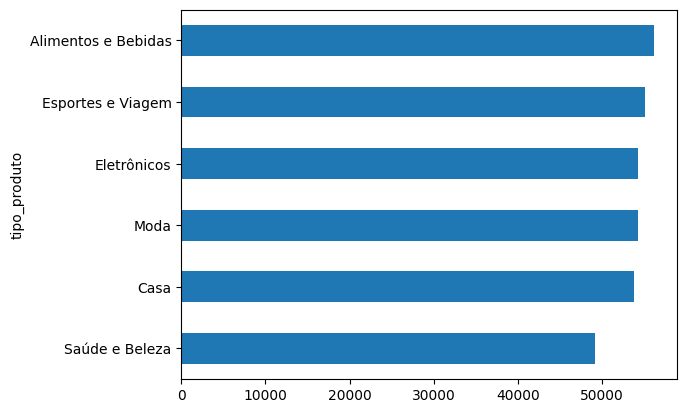

In [ ]:
query_engine = PandasQueryEngine(df=df, verbose=True, synthesize_response=True)

response = query_engine.query('Qual é a forma de pagamento mais utilizada pelos clientes?')
print("Resposta da query: ", response)
resultado = df['forma_pagamento'].value_counts().idxmax()
print("Resultado da consulta 1:\n ", resultado)
print("-"*30)
response2 = query_engine.query('Qual é o tipo de produto com maior quantidade por filial?')
print("Resposta da query_2: ", response2)
resultado2 = df.groupby(['filial','tipo_produto'])['quantidade'].sum().groupby(level=0).idxmax().apply(lambda x: x[1])
print("Resultado da consulta 2:\n ", resultado2)
print("-"*30)

import textwrap

def formatar_texto(response):
  texto = response.response
  texto_formatado = textwrap.fill(texto, width=100)
  print("Resultado da consulta com função:\n", texto_formatado)

formatar_texto(response2)

print("-"*30)
response3 = query_engine.query('''Você pode plotar o valor total por tipo de produto,
ordenando do menor para o maior e mantendo as barras na horizontal?''')

Conteúdo do arquivo `requirements.txt`:

```
pandas==2.2.2
gradio==5.4.0
llama-index==0.11.20
llama-index-llms-groq==0.2.0
llama-index-experimental==0.4.0
fpdf==1.7.2
```